In [1]:
from hurobo.utils.notebook import setup_notebook

ROOT = setup_notebook()

# Recorded dataset and its replay in the scaled LIBERO scene

The cleaned real clip `test_03` (cut from `cuts.json`, see `10_clip_cleaning.ipynb`), from recording to robot:

1. the recorded dataset: the original video with marker outlines, hand skeleton, the demo's TCP (projected from the dataset's table-frame values) with its path, the bowl and plate centres and a gripper symbol driven by the pinch aperture; the LeRobot episode as a consumer reads it; interactive TCP path and aperture;
2. the human's bowl and plate positions mapped into the sim (clamped into the work area) and checked against what the sim placed;
3. the retargeted demo replayed by the robot from its home pose;
4. dataset and replay side by side.

Modules shown: `hurobo.demo_overlay`, `hurobo.human_dataset`, `hurobo.recording`, `hurobo.generate`, `hurobo.scaled_native`. Real clip, nothing synthetic. Needs `data/raw/e1/test_03.mp4`, `data/e1/demos/test_03.npz` and `data/e1/human` (from `scripts/02_extract_demos.py --cuts` and `scripts/11_export_human_dataset.py`).

In [2]:
from hurobo.camera import CameraIntrinsics
from hurobo.demo import HumanDemo
from hurobo.demo_overlay import DemoOverlay
from hurobo.real_setup import DEFAULT_MEASUREMENTS, RealSetup
from hurobo.recording import diagnose_capture
from hurobo.utils.notebook import existing_paths, show_video

paths = existing_paths(
    {"demo": ROOT / "data/e1/demos/test_03.npz", "dataset": ROOT / "data/e1/human"},
    "run scripts/02_extract_demos.py and scripts/11_export_human_dataset.py",
)
intrinsics = CameraIntrinsics.load(ROOT / "data/camera_intrinsics_s10e.npz")
demo = HumanDemo.load(paths["demo"])
diagnosis = diagnose_capture(ROOT / demo.source_video, intrinsics, RealSetup.load(DEFAULT_MEASUREMENTS))
print(f"{len(demo.timestamps_s)} samples over {demo.timestamps_s[-1]:.1f} s")
print(f"starting at {demo.source_start_time_s:.2f} s of the clip")
print(f"grasp at sample {demo.grasp_frame_idx}, release at sample {demo.release_frame_idx}")

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792181029.460163  247822 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792181029.468549  247822 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792181029.608284  247823 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


W0000 00:00:1792181069.950196  248677 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792181069.960751  248677 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


199 samples over 9.9 s
starting at 2.70 s of the clip
grasp at sample 62, release at sample 159


## Overlay on the recorded video

In [3]:
overlay = DemoOverlay(demo, diagnosis, intrinsics)
show_video(overlay.write_video(ROOT / "results/recorded_dataset/test_03_overlay.mp4"), width=720)

## The LeRobot episode as a consumer reads it

Phone image, TCP path in the table frame, aperture, `observation.state` and `action` on one clock (from the exported dataset, not from the `.npz`).

In [4]:
from lerobot.datasets.lerobot_dataset import LeRobotDataset

from hurobo.human_dataset import describe_features, write_episode_dashboard_video

dataset = LeRobotDataset("local/hurobo_human_demos", root=paths["dataset"], video_backend="pyav")
print(f"episodes={dataset.num_episodes} frames={dataset.num_frames} fps={dataset.fps}")
print("\n".join(describe_features(dataset)))
show_video(
    write_episode_dashboard_video(
        dataset,
        0,
        ROOT / "results/recorded_dataset/episode_0.mp4",
        close_threshold_m=0.03,
        open_threshold_m=0.05,
    ),
    width=960,
)

episodes=1 frames=199 fps=20
observation.images.phone     video    (360, 640, 3)
observation.state            float32  (4,)
action                       float32  (4,)
observation.bowl_pose        float32  (7,)
observation.plate_pose       float32  (7,)


## Interactive: TCP path and gripper aperture

In [5]:
from hurobo.utils.viewer import aperture_figure, trajectory_figure

trajectory_figure(demo.tcp_pos_table, demo.is_grasping, title="test_03: TCP in the table frame (m)").show()
aperture_figure(
    demo.timestamps_s,
    demo.pinch_aperture_m,
    diagnosis.close_threshold_m,
    diagnosis.open_threshold_m,
    demo.grasp_frame_idx,
    demo.release_frame_idx,
    title="test_03: pinch aperture (the gripper opening)",
).show()

## Human layout to sim layout

The bowl and plate positions of the clip, mapped from the table frame to the sim world. A layout outside the work area (the arm's reach) would be skipped; `clamp_to_workspace=True` snaps it in.

In [6]:
import pandas as pd

from hurobo.generate import DemoGenerator
from hurobo.scaled_native import ScaledNativeScene

setup = RealSetup.load(DEFAULT_MEASUREMENTS)
scene = ScaledNativeScene(setup, seed=0)
generator = DemoGenerator(scene, [demo])
raw_layout = generator.layout_of_demo(demo)
layout = generator.layout_of_demo(demo, clamp_to_workspace=True)
scene.reset(layout)
placed = scene.object_xy()
pd.DataFrame(
    {
        "mapped (m)": {"bowl": raw_layout.bowl_xy.round(3), "plate": raw_layout.plate_xy.round(3)},
        "clamped (m)": {"bowl": layout.bowl_xy.round(3), "plate": layout.plate_xy.round(3)},
        "placed in sim (m)": {"bowl": placed.bowl_xy.round(3), "plate": placed.plate_xy.round(3)},
        "inside work area": {
            "bowl": scene.workspace.contains(raw_layout.bowl_xy),
            "plate": scene.workspace.contains(raw_layout.plate_xy),
        },
    }
)

[robosuite WARNING] No private macro file found! (__init__.py:7)


[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)


[robosuite WARNING] To setup, run: python /home/eeschner/alfredo/workspace/hurobo/.venv/lib/python3.12/site-packages/robosuite/scripts/setup_macros.py (__init__.py:9)


Creating LIBERO envs | suites=['libero_goal'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[8]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_goal | task_id=8 | n_envs=1
Local assets not found. Downloading from HuggingFace Hub...
Assets already downloaded at /home/eeschner/.cache/libero/assets


/home/eeschner/alfredo/workspace/hurobo/.venv/lib/python3.12/site-packages/robosuite/utils/binding_utils.py:1010: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  self.qpos[addr] = value


,mapped (m),clamped (m),placed in sim (m),inside work area
bowl,"[0.081, 0.122]","[0.08, 0.122]","[0.08, 0.122]",False
plate,"[0.058, -0.183]","[0.058, -0.183]","[0.058, -0.183]",True


Top-down view of the scaled scene with the aligned bowl and plate:

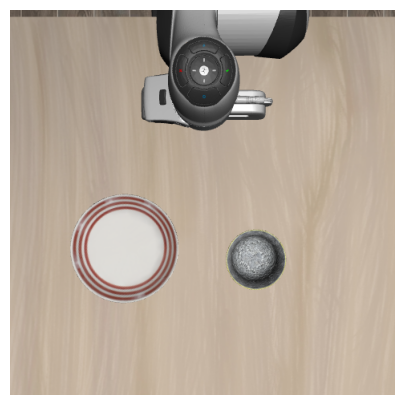

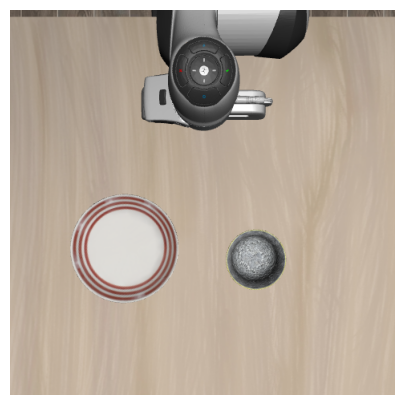

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(scene.render_top_down())
ax.axis("off")
fig

## Replay in the LIBERO scene

The demo retargeted onto the human's own bowl and plate positions and executed by the robot from its home pose.

In [8]:
replay_path = ROOT / "results/recorded_dataset/test_03_replay.mp4"
result, layout, eef_path = generator.replay_on_own_layout(demo, replay_path)
print("success" if result.success else f"failed: {result.failure}", f"({result.steps} steps)")
show_video(replay_path, width=480)

/home/eeschner/alfredo/workspace/hurobo/.venv/lib/python3.12/site-packages/robosuite/utils/binding_utils.py:1010: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  self.qpos[addr] = value


failed: timeout (800 steps)


## Dataset and replay side by side, real time

Left: the recorded clip with the dataset's TCP, hand and gripper overlay. Right: the robot replay. One real-time clock; the shorter one holds its last frame. They drift apart because the robot has its own timing (home start, half speed, gripper dwell, a stalled carry).

In [9]:
from hurobo.utils.video import write_side_by_side_video

side_by_side = write_side_by_side_video(
    ROOT / "results/recorded_dataset/test_03_overlay.mp4",
    replay_path,
    ROOT / "results/recorded_dataset/test_03_side_by_side.mp4",
    labels=("recorded dataset", "LIBERO replay"),
)
show_video(side_by_side, width=960)

## Human slowed to the robot's speed limit, replayed again

The robot's speed limit is measured from the replay above (a high percentile of its end-effector speed). The whole human demo is slowed by the factor that brings the speed of the part the robot replays within that limit, and the robot replay is generated again from the slowed demo. The robot's motion is driven by goals, not by the demo's clock, so the new replay is expected to match the first up to simulator noise (two identical replays differ by about 1 cm); the comparison below checks that.

In [10]:
import numpy as np

factor, robot_limit = generator.slowdown_to_robot(demo, eef_path)
print(f"robot limit {robot_limit:.2f} m/s -> human slowed x{factor:.2f}")
slowed_demo = demo.time_scaled(factor)
slowed_replay_path = ROOT / "results/recorded_dataset/test_03_replay_slowed.mp4"
slowed_result, _, slowed_eef_path = generator.replay_on_own_layout(slowed_demo, slowed_replay_path)
print(
    "success" if slowed_result.success else f"failed: {slowed_result.failure}",
    f"({slowed_result.steps} steps)",
)
print(
    f"largest end-effector difference to the first replay: {np.abs(slowed_eef_path - eef_path).max() * 100:.1f} cm"
)

robot limit 0.15 m/s -> human slowed x3.12


failed: timeout (800 steps)
same robot motion as the first replay: False


## Approach and grasp synchronised

Each side plays at its own speed (the human at 1/factor) and waits at an event until the other side reaches it: the human is paused while the robot goes from its home pose to the start of the approach, then both go through the approach to the grasp (the first one there waits for the other), then the carry.

In [11]:
from hurobo.generate import FPS
from hurobo.utils.video import write_phase_aligned_video

aligned = write_phase_aligned_video(
    ROOT / "results/recorded_dataset/test_03_overlay.mp4",
    slowed_replay_path,
    ROOT / "results/recorded_dataset/test_03_synchronised.mp4",
    labels=("recorded dataset", "LIBERO replay"),
    left_events_s=overlay.event_times_s(),
    right_events_s=slowed_result.event_times_s(FPS),
    slowdowns=(factor, 1.0),
    pause_faster=True,
)
show_video(aligned, width=960)

The same from the command line:

```bash
uv run python scripts/02_extract_demos.py data/raw/e1/test_03.mp4 --setup data/raw/setup_01/measurements.yaml --intrinsics data/camera_intrinsics_s10e.npz --cuts data/raw/e1/cuts.json --out data/e1/demos
MUJOCO_GL=egl uv run python scripts/03_replay.py data/e1/demos --setup data/raw/setup_01/measurements.yaml --out data/e1/replay --clamp-layout
```